![Banner](../images/09_03_banner_rs_rader.png)


# NISAR GCOV: Geocoded Polarimetric Covariance Processing

This notebook reads the NISAR Level-2 GCOV product for coastal Bangladesh, subsets it to `AOI_coastal.geojson`, and visualizes the HH and HV covariance terms with GeoLattice.


## Overview

The supplied granule contains two diagonal covariance terms (`HHHH` and `HVHV`), so the examples use dual-polarization indices rather than claiming a full quad-polarimetric covariance matrix.


## Core concepts

### Learning objectives

1. Inspect GCOV identification metadata and the frequencyA grid with `nisar.read_identification` and `nisar.inspect_hdf5`.
2. Confirm the granule stores HHHH and HVHV on a 10 m EPSG:32646 grid, and does not support full quad-pol decomposition.
3. Select the AOI window from the projected coordinate axes and view `AOI_coastal.geojson` on satellite imagery.
4. Stream the AOI in bounded chunks, exclude invalid mask values, and block-average linear gamma0 and RTC-scaled sigma0.
5. Compute the HV/HH ratio and dual-pol RVI with `nisar.gcov_indices`.
6. Lee-filter linear sigma0, convert the filtered layers to dB for display, and build a dual-polarization RGB composite.
7. Attach the GCOV EPSG code and clip the aggregated layers to the AOI polygon with rioxarray.

### Contents

1. Processing overview and limitations
2. Inspect the product and covariance layers
3. Select the AOI and inspect it on satellite imagery
4. Stream and aggregate the covariance layers
5. Dual-polarization indices and GeoLattice filtering
6. Georeference and clip the outputs to the AOI
7. Dual-polarization RGB composite
8. Optionally export AOI quick looks
9. Summary, exercises and references


## Processing overview and limitations

GCOV is a geocoded Level-2 covariance product on a projected map grid. Unlike the complex GSLC, GCOV stores averaged real covariance terms and associated product masks. This scene is on a 10 m EPSG:32646 grid and contains `HHHH` and `HVHV`, representing co-polarized and cross-polarized power terms. It does not contain `VVVV` or the cross-covariance terms needed for full quad-pol analysis.

The AOI subset is read from HDF5 in bounded chunks and block-averaged to approximately 100 m for visualization. The HHHH/HVHV layers are inspected as linear gamma0 covariance terms; the provided `rtcGammaToSigmaFactor` is applied pixel-by-pixel to derive an approximate sigma0 view. GeoLattice Lee filtering and dB conversion are used for display. This is not a substitute for inspecting calibration, masks, and product specification when doing quantitative analysis.


**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Import libraries, locate the NISAR GCOV HDF5 scene and the AOI GeoJSON on
# disk, and sanity-check that both files actually exist before any later cell
# tries to open them.

from pathlib import Path

import geopandas as gpd  # vector data (the AOI)
import h5py  # read NISAR HDF5 files
import leafmap  # interactive web maps
import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import rioxarray  # registers the .rio accessor
import xarray as xr  # labelled rasters

from geolattice import rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.sar import nisar  # NISAR helpers

# 1. Render figures at a slightly higher DPI than the matplotlib default so
#    the covariance/dB panels later in the notebook are easier to read.
plt.rcParams.update({"figure.dpi": 110})

# 2. Resolve the data directory so the notebook runs both from the repo root
#    (e.g. in CI) and from this notebook's own folder (typical interactive
#    use), falling back to a local "../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd" folder in the latter case.
DATA_RELATIVE = Path("Data/08_remote_sensing/08_03_radar/NISAR_bd")
if not DATA_RELATIVE.exists():  # when run from the repository root instead of this folder
    DATA_RELATIVE = Path("../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd")  # use the path from the root
DATA_DIR = DATA_RELATIVE  # the data folder

# 3. Point at the specific GCOV granule (frequency-A, dual-pol HH/HV) and its
#    matching AOI polygon, then fail fast with a clear message if either file
#    is missing rather than letting a later cell raise an opaque HDF5 error.
SCENE = DATA_DIR / (
    "NISAR_L2_PR_GCOV_031_069_A_013_4005_DHDH_A_20260922T232058_"
    "20260922T232133_P05023_N_F_J_001.h5"
)
AOI_PATH = DATA_DIR / "AOI_coastal.geojson"  # the coastal AOI polygon
assert SCENE.is_file(), f"NISAR GCOV file not found: {SCENE.resolve()}"  # stop if the GCOV file is missing
assert AOI_PATH.is_file(), f"AOI GeoJSON not found: {AOI_PATH.resolve()}"  # stop if the AOI file is missing

# 4. Echo the resolved paths and the installed GeoLattice version so the notebook
#    output records exactly what was read, which helps with reproducibility.
print(f"GeoLattice remote sensing version: {rs.__version__}")
print(f"GCOV: {SCENE.name}")  # the GCOV file
print(f"AOI:  {AOI_PATH}")  # the AOI file

GeoLattice remote sensing version: 0.3.49
GCOV: NISAR_L2_PR_GCOV_031_069_A_013_4005_DHDH_A_20260922T232058_20260922T232133_P05023_N_F_J_001.h5
AOI:  ../../../../Data/08_remote_sensing/08_03_radar/NISAR_bd/AOI_coastal.geojson


## Inspect the product and covariance layers

GeoLattice reads the product identification metadata and inventories the frequency-A grid. This inventory reports dataset shapes and metadata without loading the multi-gigabyte covariance arrays.


In [2]:
# Inspect the GCOV product identification metadata and the frequency-A grid
# layout without loading the full (multi-gigabyte) covariance arrays.

# 1. Read the product identification group (mission, product type/level,
#    track/frame, orbit direction, zero-Doppler time window, DOI, ...) and
#    print only the keys that are actually present in this granule.
identification = nisar.read_identification(SCENE, "GCOV")
# list the datasets of the frequency-A grid
grid_info = nisar.inspect_hdf5(SCENE, "/science/LSAR/GCOV/grids/frequencyA")

for key in (  # identification fields to show
    "missionId", "productType", "productLevel", "productVersion",
    "trackNumber", "frameNumber", "orbitPassDirection", "lookDirection",
    "zeroDopplerStartTime", "zeroDopplerEndTime", "productDoi",
):
    if key in identification:  # print only the fields that are present
        print(f"{key}: {identification[key]}")  # field name and value

# 2. Open the frequency-A grid group directly with h5py (read-only, closed
#    automatically by the "with" block) to pull out the small, cheap-to-read
#    scalars and 1-D coordinate axes needed for the rest of the notebook:
#    which covariance terms/polarizations exist, the overall raster shape,
#    the projection (EPSG code) and pixel spacing, and the x/y coordinate
#    axes used later to compute AOI row/column windows.
GRID = "/science/LSAR/GCOV/grids/frequencyA"
with h5py.File(SCENE, "r") as f:  # open the GCOV file
    grid = f[GRID]  # the frequency-A grid group
    image_shape = grid["HHHH"].shape  # size of the HHHH grid
    # covariance terms in the file (decoded from bytes)
    covariance_terms = [v.decode() if isinstance(v, bytes) else str(v)
                        for v in grid["listOfCovarianceTerms"][:]]
    polarizations = [v.decode() if isinstance(v, bytes) else str(v)  # polarisations (decoded from bytes)
                     for v in grid["listOfPolarizations"][:]]
    epsg = int(grid["projection"][()])  # EPSG code of the map projection
    x_spacing = float(grid["xCoordinateSpacing"][()])  # pixel spacing in x (m)
    y_spacing = float(grid["yCoordinateSpacing"][()])  # pixel spacing in y (m, negative: north-up)
    x_axis = grid["xCoordinates"][:]  # x coordinate of every column
    y_axis = grid["yCoordinates"][:]  # y coordinate of every row
    print(f"Covariance terms: {covariance_terms}")  # the covariance terms
    print(f"Polarizations: {polarizations}")  # the polarisations
    print(f"Grid: {image_shape[0]:,} rows x {image_shape[1]:,} columns")  # grid size
    print(f"CRS: EPSG:{epsg}; spacing: {x_spacing:g} m x {abs(y_spacing):g} m")  # CRS and pixel spacing
    # meaning of the gamma0-to-sigma0 factor
    print(f"RTC gamma0-to-sigma0 factor: {grid['rtcGammaToSigmaFactor'].attrs.get('description', '')}")

# 3. From the lightweight inventory gathered above (shapes/dtypes/attrs only,
#    no pixel data), show a compact summary table restricted to the datasets
#    this notebook actually uses later: the two diagonal covariance terms,
#    the valid-data mask, the number-of-looks layer, the RTC scaling factor,
#    the coordinate axes, and the projection scalar.
[(path.rsplit("/", 1)[-1], info["shape"], info["dtype"], info["attrs"].get("description"))
 for path, info in grid_info.items()
 if path.rsplit("/", 1)[-1] in (
     "HHHH", "HVHV", "mask", "numberOfLooks", "rtcGammaToSigmaFactor",
     "xCoordinates", "yCoordinates", "projection"
 )]

missionId: NISAR
productType: GCOV
productLevel: L2
productVersion: 1.0.11
trackNumber: 69
frameNumber: 13
orbitPassDirection: Ascending
lookDirection: Left
zeroDopplerStartTime: 2026-09-22T23:20:58.000000000
zeroDopplerEndTime: 2026-09-22T23:21:33.999342105
productDoi: 10.5067/NIL2GCOV-P1
Covariance terms: ['HHHH', 'HVHV']
Polarizations: ['HH', 'HV']
Grid: 33,552 rows x 34,200 columns
CRS: EPSG:32646; spacing: 10 m x 10 m
RTC gamma0-to-sigma0 factor: b'Radiometric terrain correction (RTC) scaling factor to normalize backscatter coefficients from gamma0 to sigma0, accounting for local terrain'


[('HHHH', (33552, 34200), 'float32', 'Covariance between HH and HH'),
 ('HVHV', (33552, 34200), 'float32', 'Covariance between HV and HV'),
 ('mask',
  (33552, 34200),
  'uint8',
  'Mask indicating the subswath number associated with valid GCOV samples. A GCOV sample is only considered valid if it is generated from fully-focused radar samples. If at least one radar sample in the averaging set is partially focused or invalid, the corresponding mask pixel will contain the value 0. GCOV pixels outside of the radar acquisition extent are filled with the value 255'),
 ('numberOfLooks',
  (33552, 34200),
  'float32',
  'Number of averaged radar-grid pixels for covariance estimation'),
 ('projection',
  (),
  'uint32',
  'Product map grid projection: EPSG code, with additional projection information as HDF5 Attributes'),
 ('rtcGammaToSigmaFactor',
  (33552, 34200),
  'float32',
  'Radiometric terrain correction (RTC) scaling factor to normalize backscatter coefficients from gamma0 to sigma0, 

## Select the AOI and inspect it on satellite imagery

The GCOV is already geocoded. The AOI is transformed into the product CRS to calculate the exact row/column subset from the coordinate axes. Leafmap displays the supplied polygon over Esri World Imagery as a geographic context check; the subset itself remains based on the GCOV projected grid.


In [3]:
# Load the AOI polygon, convert it into the GCOV map grid's CRS to find the
# exact row/column subset to read, and plot the AOI over satellite imagery
# as an independent visual check that it lands where expected.

# 1. Read the AOI GeoJSON and guard against an empty file. If the file has
#    no CRS defined, assume geographic WGS84 (EPSG:4326) rather than failing
#    on the reprojection below.
aoi = gpd.read_file(AOI_PATH)
if aoi.empty:  # the AOI file has no polygon
    raise ValueError(f"AOI contains no features: {AOI_PATH}")  # stop with a clear message
if aoi.crs is None:  # assume WGS 84 when the file has no CRS
    aoi = aoi.set_crs("EPSG:4326")  # set it

# 2. Keep a lon/lat copy for the Leafmap basemap display, and reproject a
#    separate copy into the GCOV product's own projected CRS (from the
#    "epsg" variable read out of the grid in the previous cell) because the
#    row/column lookup below must be done in the product's native grid, not
#    in geographic coordinates.
aoi_ll = aoi.to_crs("EPSG:4326")
aoi_grid = aoi.to_crs(f"EPSG:{epsg}")  # the AOI in the grid's projection
min_x, min_y, max_x, max_y = aoi_grid.total_bounds  # its bounding box

# 3. Translate the AOI's projected bounding box into GCOV array indices by
#    finding which entries of the x/y coordinate axes fall inside it. This
#    works directly because GCOV is already geocoded onto a regular grid,
#    unlike a range/azimuth radar product that would need resampling first.
row_indices = np.flatnonzero((y_axis >= min_y) & (y_axis <= max_y))
column_indices = np.flatnonzero((x_axis >= min_x) & (x_axis <= max_x))  # columns inside the AOI
if row_indices.size == 0 or column_indices.size == 0:  # no overlap
    raise ValueError("The AOI does not overlap the GCOV map grid")  # stop with a clear message
row_start, row_stop = int(row_indices[0]), int(row_indices[-1] + 1)  # first and last row (+1)
column_start, column_stop = int(column_indices[0]), int(column_indices[-1] + 1)  # first and last column (+1)
# AOI bounds in the grid CRS
print(f"AOI bounds in EPSG:{epsg}: {min_x:.1f}, {min_y:.1f}, {max_x:.1f}, {max_y:.1f}")
# the grid window
print(f"GCOV window: rows {row_start:,}:{row_stop:,}, columns {column_start:,}:{column_stop:,}")
print(f"Window size: {row_stop-row_start:,} x {column_stop-column_start:,} source pixels")  # its size

# 4. Build a quick Leafmap view centered on the AOI, draped over Esri World
#    Imagery, purely as a geographic context check (does the polygon fall
#    where it should on the coast?) - this is independent of, and does not
#    feed into, the GCOV pixel subsetting computed above.
west, south, east, north = aoi_ll.total_bounds
center = ((south + north) / 2, (west + east) / 2)  # map centre (lat, lon)
aoi_map = leafmap.Map(center=center, zoom=8, height="600px")  # an interactive map
aoi_map.add_basemap("Esri.WorldImagery")  # satellite basemap
aoi_map.add_gdf(  # add the AOI polygon
    aoi_ll,
    layer_name="Coastal AOI",
    style={"color": "#ff3b30", "weight": 3, "fillColor": "#ff3b30", "fillOpacity": 0.12},
    hover_style={"color": "#ffff00", "weight": 4, "fillOpacity": 0.2},
    zoom_to_layer=False,
)
aoi_map.add_layer_control()  # layer switcher
aoi_map  # show the map

AOI bounds in EPSG:32646: 219364.0, 2420523.2, 351768.2, 2532569.9
GCOV window: rows 15,519:26,724, columns 10,416:23,657
Window size: 11,205 x 13,241 source pixels


Map(center=[np.float64(22.38019), np.float64(90.91958)], controls=(ZoomControl(options=['position', 'zoom_in_t…

## Stream and aggregate the covariance layers

The GCOV scene is large, so this cell reads only AOI rows and columns in bounded chunks. Each output cell aggregates covariance in linear units; dB conversion happens later. The source mask marks valid subswath values from 1 through 254. Values 0 (partially focused/invalid) and 255 (outside the acquisition) are excluded. The RTC factor is applied per source pixel before aggregating sigma0, not after averaging.


In [4]:
# Stream only the AOI rows/columns of the GCOV covariance terms from HDF5 in
# bounded row chunks, mask out invalid/out-of-swath pixels, apply the RTC
# gamma0-to-sigma0 factor per source pixel, and block-average down to a
# coarser display grid - all without ever loading the full scene into memory.

LOOKS = (10, 10)  # 10 m GCOV pixels -> approximately 100 m display cells
OUTPUT_ROWS_PER_CHUNK = 4  # aggregated rows computed per read

# block averages of gamma0, sigma0 and the RTC factor, read chunk by chunk
def stream_gcov_window(grid_group, window, looks=LOOKS,
                       output_rows_per_chunk=OUTPUT_ROWS_PER_CHUNK):
    """Block-average valid dual-pol GCOV gamma0, sigma0, and RTC factor."""
    # 1. Snap the requested window down to a whole number of output blocks
    #    (out_rows x out_columns at the given "looks" factor) so every block
    #    below is uniformly sized; a window smaller than one block is an error.
    row0, row1, col0, col1 = window
    look_y, look_x = looks  # looks in y and x
    out_rows = (row1 - row0) // look_y  # output rows
    out_columns = (col1 - col0) // look_x  # output columns
    if out_rows < 1 or out_columns < 1:  # window smaller than one block
        # stop with a clear message
        raise ValueError("AOI window is smaller than the selected aggregation factors")
    row1 = row0 + out_rows * look_y  # trim to whole blocks
    col1 = col0 + out_columns * look_x  # trim to whole blocks

    # 2. Pre-allocate NaN-filled output arrays for every layer this function
    #    produces, so any output block that ends up with zero valid source
    #    pixels is correctly left as NaN rather than 0.
    names = ("hh_gamma0", "hv_gamma0", "hh_sigma0", "hv_sigma0", "rtc_factor")
    # one output array per layer
    output = {name: np.full((out_rows, out_columns), np.nan, dtype="float32") for name in names}

    # 3. Walk down the output grid a few rows at a time (output_rows_per_chunk)
    #    rather than reading the whole AOI window at once, which keeps peak
    #    memory bounded regardless of how large the AOI is.
    for out0 in range(0, out_rows, output_rows_per_chunk):
        count = min(output_rows_per_chunk, out_rows - out0)  # output rows in this chunk
        source0 = row0 + out0 * look_y  # first source row
        source1 = source0 + count * look_y  # last source row
        row_slice, col_slice = slice(source0, source1), slice(col0, col1)  # row and column slices of the chunk

        # 4. Read this chunk's source pixels for both diagonal covariance
        #    terms, the RTC gamma0-to-sigma0 factor, and the product mask.
        hh = grid_group["HHHH"][row_slice, col_slice]
        hv = grid_group["HVHV"][row_slice, col_slice]  # HV backscatter (gamma0) of the chunk
        # gamma0-to-sigma0 factor of the chunk
        factor = grid_group["rtcGammaToSigmaFactor"][row_slice, col_slice]
        mask = grid_group["mask"][row_slice, col_slice]  # the product's validity mask

        # 5. Build the valid-pixel mask: the GCOV mask convention treats 0 as
        #    partially focused/invalid and 255 as outside the acquisition, so
        #    only values 1-254 denote valid subswath coverage. Also drop any
        #    non-finite values and physically impossible (negative) power.
        valid = (mask > 0) & (mask < 255)
        # drop NaN, non-positive HH and negative HV
        valid &= np.isfinite(hh) & np.isfinite(hv) & (hh > 0) & (hv >= 0)

        # 6. Derive sigma0 from gamma0 by applying the RTC factor per source
        #    pixel (before averaging), since the factor itself varies pixel
        #    to pixel and averaging first would give a biased result.
        blocks = {
            "hh_gamma0": hh,
            "hv_gamma0": hv,
            "hh_sigma0": hh * factor,
            "hv_sigma0": hv * factor,
            "rtc_factor": factor,
        }
        # 7. For each layer, reshape the chunk into (rows, look_y, cols, look_x)
        #    blocks, sum only the valid entries per block, divide by the count
        #    of valid entries, and store NaN for any block with no valid data
        #    at all - i.e. a masked block-average in linear units.
        for name, layer in blocks.items():
            layer_valid = valid & np.isfinite(layer)  # valid values of this layer
            layer_blocks = layer.reshape(count, look_y, out_columns, look_x)  # values grouped into blocks
            # validity grouped into blocks
            valid_layer_blocks = layer_valid.reshape(count, look_y, out_columns, look_x)
            # sum of valid values per block
            totals = np.where(valid_layer_blocks, layer_blocks, 0).sum(axis=(1, 3))
            n_valid = valid_layer_blocks.sum(axis=(1, 3))  # number of valid values per block
            output[name][out0:out0 + count] = np.divide(  # mean per block
                totals, n_valid,
                out=np.full((count, out_columns), np.nan, dtype="float32"),
                where=n_valid > 0,
            )
    return output  # the aggregated layers

# 8. Snap the AOI window from the previous cell down to a whole number of
#    LOOKS-sized output blocks (mirrors the snapping done inside the
#    function) so the output coordinate axes built below line up exactly
#    with the aggregated arrays returned by stream_gcov_window.
n_output_rows = (row_stop - row_start) // LOOKS[0]
n_output_columns = (column_stop - column_start) // LOOKS[1]  # output columns
row_stop = row_start + n_output_rows * LOOKS[0]  # trim to whole blocks
column_stop = column_start + n_output_columns * LOOKS[1]  # trim to whole blocks
window = (row_start, row_stop, column_start, column_stop)  # the final window
with h5py.File(SCENE, "r") as f:  # open the GCOV file
    gcov = stream_gcov_window(f[GRID], window)  # aggregate the AOI window

# 9. Build the coarse output x/y coordinate axes as the mean position of
#    each block of source pixels it was aggregated from, so the downsampled
#    arrays carry geographically meaningful coordinates for later plotting
#    and clipping.
out_x = x_axis[column_start:column_stop].reshape(n_output_columns, LOOKS[1]).mean(axis=1)
# y coordinate of every output row
out_y = y_axis[row_start:row_stop].reshape(n_output_rows, LOOKS[0]).mean(axis=1)
coords = {"y": out_y, "x": out_x}  # coordinates of the output grid
print(f"Aggregated GCOV grid: {n_output_rows:,} rows x {n_output_columns:,} columns")  # grid size
print(f"Valid HH gamma0 fraction: {np.isfinite(gcov['hh_gamma0']).mean():.1%}")  # valid HH share
print(f"Valid HV gamma0 fraction: {np.isfinite(gcov['hv_gamma0']).mean():.1%}")  # valid HV share
print(f"Mean RTC gamma0-to-sigma0 factor: {np.nanmean(gcov['rtc_factor']):.3f}")  # mean gamma0-to-sigma0 factor

Aggregated GCOV grid: 1,120 rows x 1,324 columns
Valid HH gamma0 fraction: 100.0%
Valid HV gamma0 fraction: 100.0%
Mean RTC gamma0-to-sigma0 factor: 0.744


## Dual-polarization indices and GeoLattice filtering

GeoLattice `nisar.gcov_indices` computes the HV/HH ratio and dual-pol RVI from linear gamma0 covariance terms. Since this granule has no VVVV term, quad-pol RVI and HH/VV ratio are intentionally not computed. GeoLattice Lee filtering is applied to linear sigma0 quick looks; the filtered layers are converted to dB only for display.


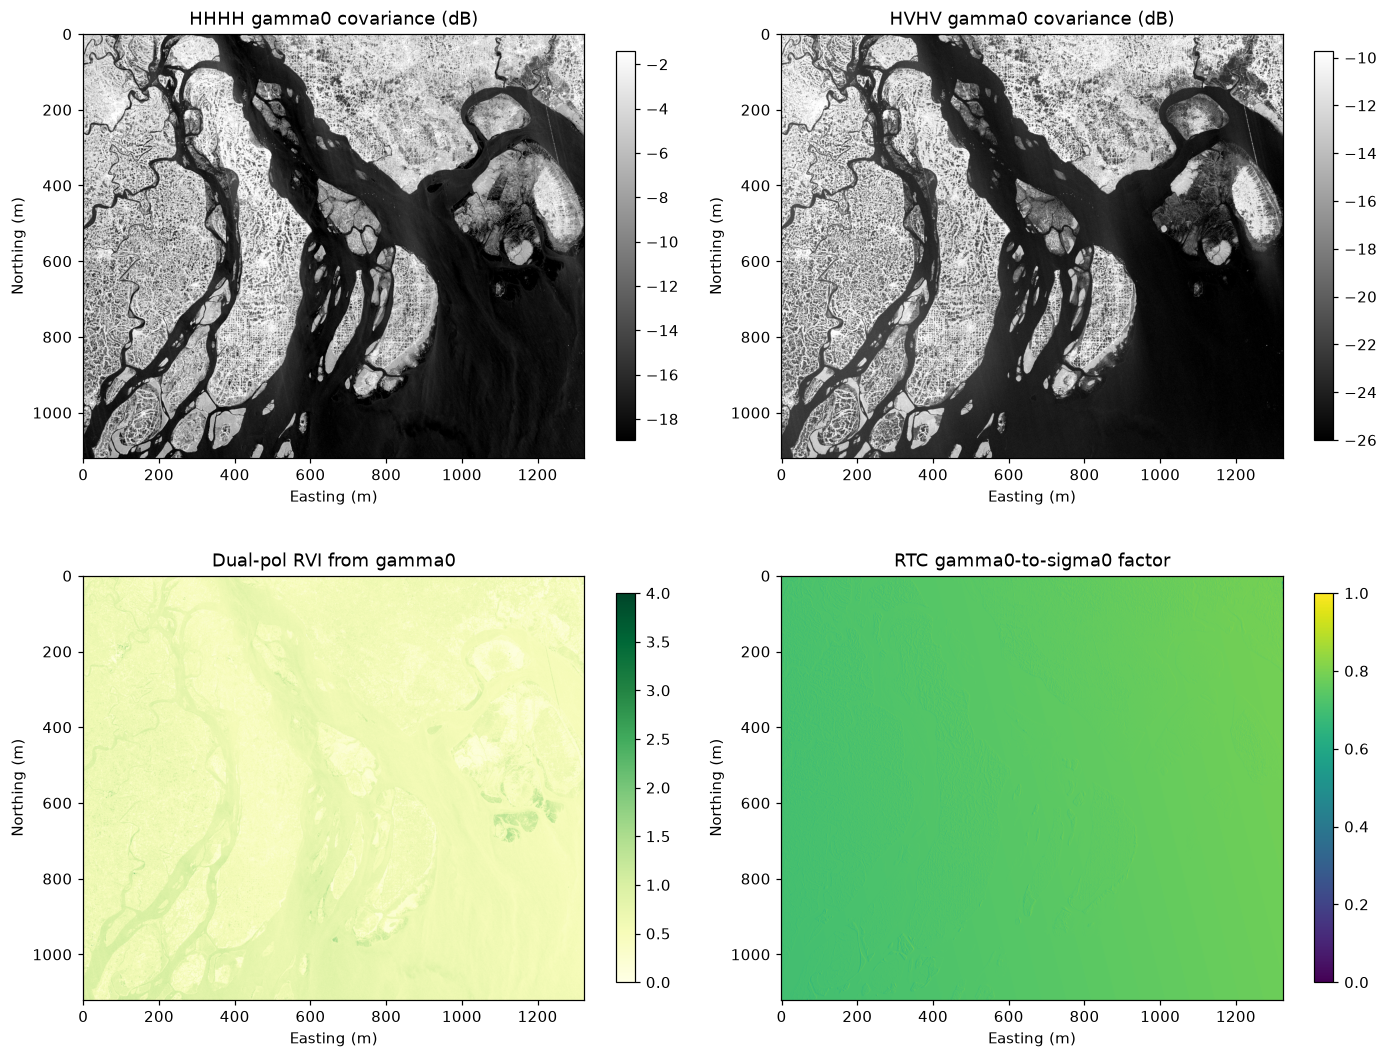

In [5]:
# Wrap the aggregated numpy arrays as labeled xarray DataArrays, compute
# dual-polarization indices from the linear gamma0 covariance terms, apply
# GeoLattice Lee speckle filtering to the sigma0 quick looks, convert to dB for
# display only, and plot a 2x2 panel of covariance/index/RTC layers.

# 1. Attach the shared (y, x) coordinates built in the previous cell to each
#    aggregated layer so downstream operations (indices, filtering, plotting,
#    clipping) all carry consistent geographic coordinates.
hh_gamma0 = xr.DataArray(gcov["hh_gamma0"], dims=("y", "x"), coords=coords, name="hh_gamma0")
# HV gamma0 as a DataArray
hv_gamma0 = xr.DataArray(gcov["hv_gamma0"], dims=("y", "x"), coords=coords, name="hv_gamma0")
hh_sigma0 = xr.DataArray(gcov["hh_sigma0"], dims=("y", "x"), coords=coords, name="hh_sigma0")  # HH sigma0
hv_sigma0 = xr.DataArray(gcov["hv_sigma0"], dims=("y", "x"), coords=coords, name="hv_sigma0")  # HV sigma0
# the gamma0-to-sigma0 factor
rtc_factor = xr.DataArray(gcov["rtc_factor"], dims=("y", "x"), coords=coords, name="rtc_gamma_to_sigma_factor")

# 2. Compute dual-polarization indices (HV/HH ratio and dual-pol RVI) from
#    the linear gamma0 covariance terms. Because this granule lacks VVVV,
#    only the dual-pol variants are available - quad-pol RVI and HH/VV
#    ratio require a term this scene does not contain.
dual_indices = nisar.gcov_indices(hh_gamma0, hv_gamma0)

# 3. Apply a Lee speckle filter to the linear sigma0 quick looks (not to the
#    raw gamma0 covariance terms), then convert the filtered result to dB
#    purely for display - the filtering and the index computation above
#    both operate on linear power, as speckle statistics assume.
hh_sigma0_lee = xr.DataArray(rs.sar.lee(hh_sigma0.values, size=5), dims=("y", "x"),
                             coords=coords, name="hh_sigma0_lee")
# Lee speckle filter on HV sigma0 (5 x 5)
hv_sigma0_lee = xr.DataArray(rs.sar.lee(hv_sigma0.values, size=5), dims=("y", "x"),
                             coords=coords, name="hv_sigma0_lee")
hh_sigma0_db = rs.sar.to_db(hh_sigma0_lee)  # filtered HH sigma0 in dB
hv_sigma0_db = rs.sar.to_db(hv_sigma0_lee)  # filtered HV sigma0 in dB

# 4. Plot a 2x2 panel: the two diagonal covariance terms in dB (stretched to
#    their own 2nd-98th percentile since no fixed display range applies to
#    dB covariance), the dual-pol RVI on a fixed 0-4 scale, and the RTC
#    gamma0-to-sigma0 factor on a fixed 0-1 scale, since both indices have a
#    physically meaningful range rather than a data-dependent one.
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, image, title, cmap, limits in (  # the panels: image, title, colour map and limits
    (axes[0, 0], rs.sar.to_db(hh_gamma0), "HHHH gamma0 covariance (dB)", "gray", None),
    (axes[0, 1], rs.sar.to_db(hv_gamma0), "HVHV gamma0 covariance (dB)", "gray", None),
    (axes[1, 0], dual_indices["dual_pol_rvi"], "Dual-pol RVI from gamma0", "YlGn", (0, 4)),
    (axes[1, 1], rtc_factor, "RTC gamma0-to-sigma0 factor", "viridis", (0, 1)),
):
    if limits is None:  # no fixed limits: use a 2-98 % stretch
        vmin, vmax = np.nanpercentile(image.values, [2, 98])  # stretch limits
    else:
        vmin, vmax = limits  # fixed limits
    artist = ax.imshow(image, cmap=cmap, vmin=vmin, vmax=vmax, origin="upper")  # show the image
    ax.set(title=title, xlabel="Easting (m)", ylabel="Northing (m)")  # title and axis labels
    plt.colorbar(artist, ax=ax, shrink=0.78)  # colour bar
plt.tight_layout()  # arrange
plt.show()  # draw

The covariance and index panels are visualized on the aggregated grid. The RTC factor is a product-provided normalization layer; it is not itself a terrain correction model. Check the GCOV product specification and per-layer metadata before interpreting values across scenes or processing versions.


## Georeference and clip the outputs to the AOI

The GCOV data are already map-projected. Attach the EPSG to the downsampled xarray layers, then clip to the exact supplied GeoJSON polygon using rioxarray.


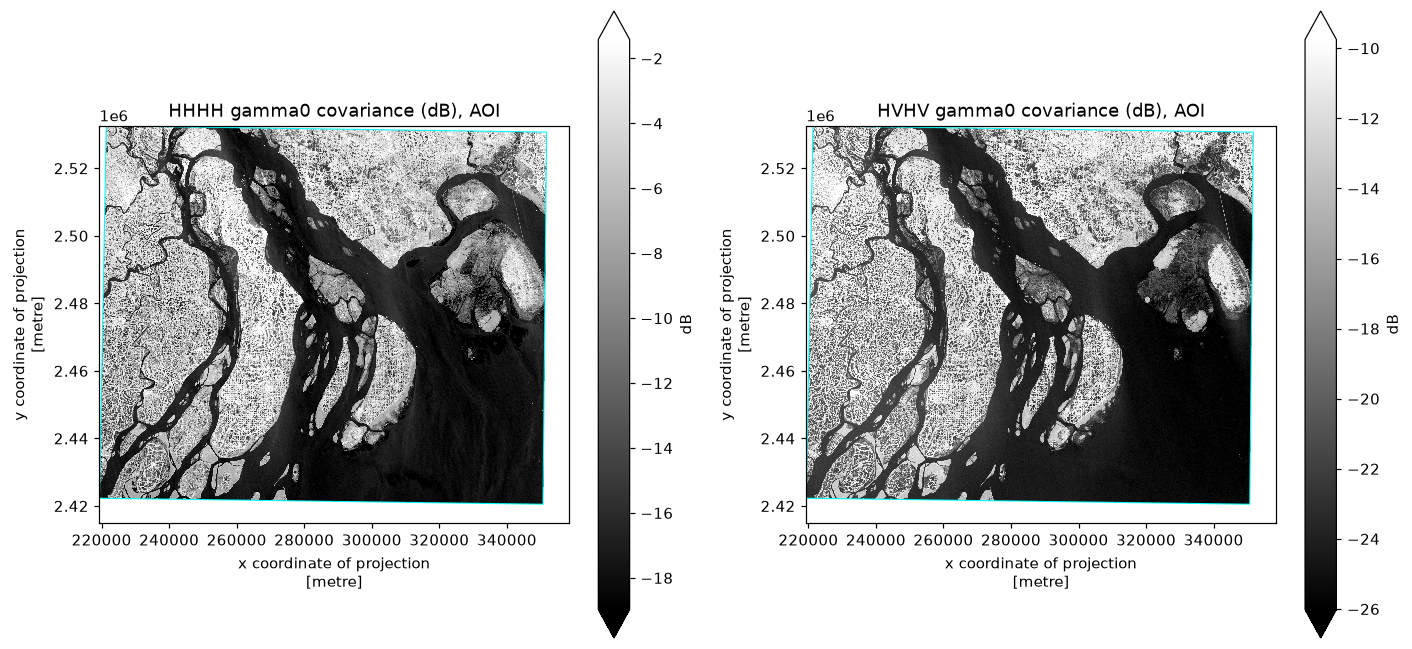

AOI output grid: 1,120 rows x 1,324 columns
CRS: EPSG:32646; source pixel spacing: 10 m


In [6]:
# Attach the GCOV product's CRS to each aggregated xarray layer and clip
# every layer to the exact AOI polygon (not just its bounding box), then plot
# the clipped HHHH/HVHV covariance panels with the AOI boundary overlaid.

def georeference_and_clip(image):
    # 1. Tell rioxarray which dimensions are x/y, stamp the GCOV grid's EPSG
    #    code onto the array (the data is already projected, so this only
    #    labels it rather than reprojecting), then clip to the AOI polygon's
    #    exact geometry. all_touched=True keeps any output pixel the polygon
    #    boundary passes through, matching the row/column window logic used
    #    when the AOI was first selected.
    return image.rio.set_spatial_dims(x_dim="x", y_dim="y").rio.write_crs(
        f"EPSG:{epsg}"
    ).rio.clip(aoi_grid.geometry, aoi_grid.crs, drop=True, all_touched=True)

# 2. Apply the same georeference-and-clip step to every aggregated layer that
#    later cells need in AOI-clipped form: both diagonal covariance terms,
#    the dual-pol RVI index, the RTC factor, and the Lee-filtered sigma0 dB
#    layers used for the RGB composite in Step 6.
hh_gamma0_aoi = georeference_and_clip(hh_gamma0)
hv_gamma0_aoi = georeference_and_clip(hv_gamma0)  # HV gamma0, clipped to the AOI
rvi_aoi = georeference_and_clip(dual_indices["dual_pol_rvi"])  # dual-pol RVI, clipped
rtc_aoi = georeference_and_clip(rtc_factor)  # RTC factor, clipped
hh_sigma0_db_aoi = georeference_and_clip(hh_sigma0_db)  # HH sigma0 in dB, clipped
hv_sigma0_db_aoi = georeference_and_clip(hv_sigma0_db)  # HV sigma0 in dB, clipped

# 3. Plot the clipped HH and HV gamma0 covariance terms in dB side by side,
#    using xarray's built-in imshow (robust=True stretches to a robust
#    percentile range automatically) with the AOI boundary drawn on top so
#    the clip extent is visually verifiable.
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, image, title in (  # the panels with their titles
    (axes[0], rs.sar.to_db(hh_gamma0_aoi), "HHHH gamma0 covariance (dB), AOI"),
    (axes[1], rs.sar.to_db(hv_gamma0_aoi), "HVHV gamma0 covariance (dB), AOI"),
):
    # show with a robust stretch
    image.plot.imshow(ax=ax, cmap="gray", robust=True, cbar_kwargs={"label": "dB"})
    aoi_grid.boundary.plot(ax=ax, color="cyan", linewidth=0.7)  # AOI outline
    ax.set_title(title)  # title
    ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

print(f"AOI output grid: {hh_gamma0_aoi.sizes['y']:,} rows x {hh_gamma0_aoi.sizes['x']:,} columns")  # grid size
print(f"CRS: {hh_gamma0_aoi.rio.crs}; source pixel spacing: {x_spacing:g} m")  # CRS and pixel spacing

## Dual-polarization RGB composite

Display red = HH sigma0 (dB), green = HV sigma0 (dB), and blue = HH−HV (dB), equivalent to the HH/HV ratio in decibels. Each channel is contrast-stretched independently from its 2nd to 98th percentile. This false-color composite is for visual interpretation only.


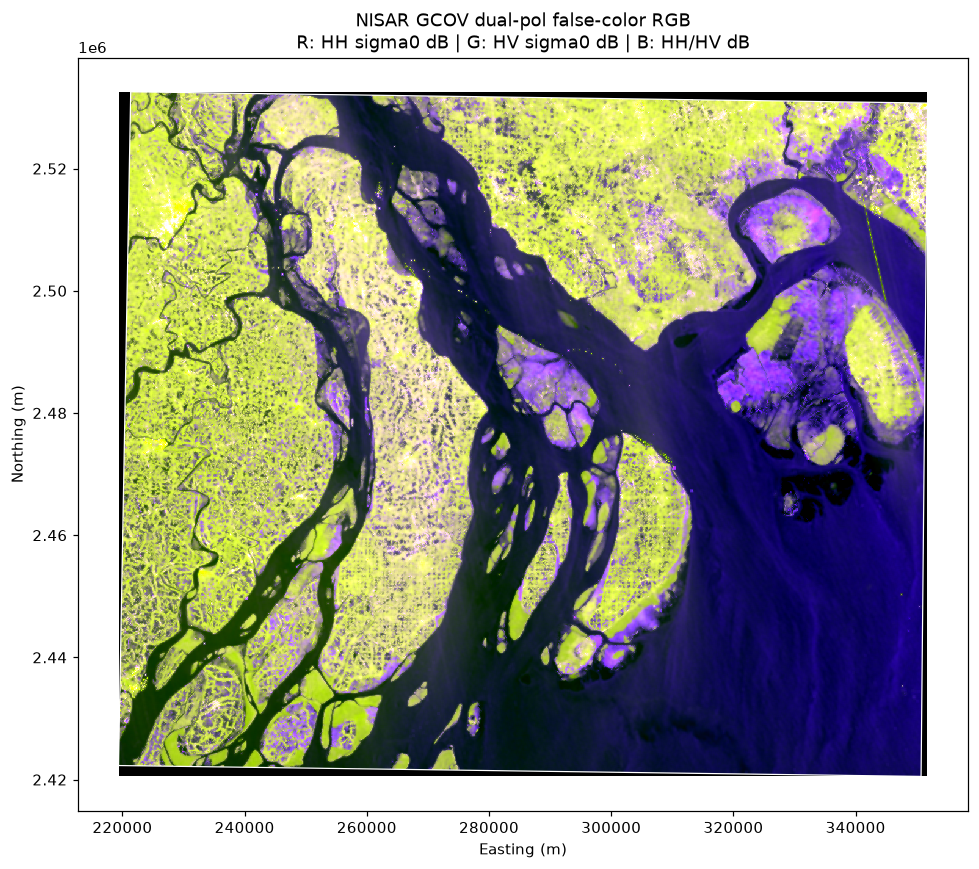

In [7]:
# Build a false-color dual-polarization RGB composite for visual
# interpretation: red = HH sigma0 (dB), green = HV sigma0 (dB), and
# blue = HH-HV (dB), i.e. the HH/HV ratio expressed in decibels.

# 1. Pull the AOI-clipped, Lee-filtered sigma0 dB arrays out as plain numpy
#    arrays and compute the HH-HV difference, which in dB space is
#    equivalent to the HH/HV linear ratio. Track which pixels are finite in
#    both channels so invalid AOI-edge pixels can be masked out uniformly.
hh_values = hh_sigma0_db_aoi.values.astype("float32")
hv_values = hv_sigma0_db_aoi.values.astype("float32")  # HV in dB
ratio_values = hh_values - hv_values  # HH minus HV (dB)
valid_rgb = np.isfinite(hh_values) & np.isfinite(hv_values)  # pixels valid in both

# stretch one channel to [0, 1] between percentiles of its valid values
def stretch_channel(values, mask, percentiles=(2, 98)):
    # 2. Contrast-stretch one channel independently of the others, using
    #    only the valid (finite) pixels to compute the 2nd/98th percentile
    #    bounds, then clip and rescale to 0-1 for display as an RGB channel.
    #    A degenerate (constant) channel is returned as all zeros rather
    #    than dividing by zero.
    finite_values = values[mask]
    if finite_values.size == 0:  # no valid values
        raise ValueError("RGB channel has no finite data inside the AOI")  # stop with a clear message
    low, high = np.percentile(finite_values, percentiles)  # percentile limits
    if high <= low:  # constant channel
        return np.zeros(values.shape, dtype="float32")  # return zeros
    return np.clip((values - low) / (high - low), 0, 1).astype("float32")  # stretch to [0, 1]

# 3. Stack the three independently stretched channels into an (rows, cols, 3)
#    RGB image (red=HH, green=HV, blue=HH-HV ratio), then force any pixel
#    that was invalid in either source channel to black rather than letting
#    it show a partially-stretched or NaN color.
rgb = np.stack((
    stretch_channel(hh_values, valid_rgb),
    stretch_channel(hv_values, valid_rgb),
    stretch_channel(ratio_values, valid_rgb),
), axis=-1)
rgb[~valid_rgb] = 0  # no-data pixels in black

# 4. Plot the composite using the AOI's own x/y coordinate extent (rather
#    than pixel indices) so it lines up with the AOI boundary overlay, and
#    use "nearest" interpolation to avoid blending real and masked pixels.
x = hh_sigma0_db_aoi.x.values
y = hh_sigma0_db_aoi.y.values  # northing values
fig, ax = plt.subplots(figsize=(9, 8))  # one panel
# the RGB composite in map coordinates
ax.imshow(rgb, extent=(x.min(), x.max(), y.min(), y.max()), origin="upper", interpolation="nearest")
aoi_grid.boundary.plot(ax=ax, color="white", linewidth=0.8)  # AOI outline
ax.set(xlabel="Easting (m)", ylabel="Northing (m)",  # axis labels and title
       title="NISAR GCOV dual-pol false-color RGB\nR: HH sigma0 dB | G: HV sigma0 dB | B: HH/HV dB")
ax.set_aspect("equal")  # equal scale
plt.tight_layout()  # arrange
plt.show()  # draw

## Optionally export AOI quick looks

Exports are disabled by default. These layers are aggregated visualizations; they are not the original full-resolution GCOV covariance data.


In [8]:
# Optionally write the AOI-clipped quick-look layers to GeoTIFF. Disabled by
# default so simply running the notebook does not write files to disk; set
# WRITE_OUTPUTS = True to export them.

WRITE_OUTPUTS = False
if WRITE_OUTPUTS:  # only when output writing is switched on
    # 1. Create an output folder alongside the source data for the exported
    #    quick looks, if it does not already exist.
    output_dir = DATA_DIR / "gcov_quicklooks"
    output_dir.mkdir(parents=True, exist_ok=True)  # create the output folder
    # 2. Export the HH and HV gamma0 covariance terms in dB, and the dual-pol
    #    RVI index, as LZW-compressed GeoTIFFs. These are the aggregated,
    #    AOI-clipped visualization layers computed above, not the original
    #    full-resolution GCOV covariance arrays.
    rs.sar.to_db(hh_gamma0_aoi).rio.to_raster(
        output_dir / "NISAR_GCOV_HHHH_gamma0_db_quicklook.tif", compress="LZW"
    )
    rs.sar.to_db(hv_gamma0_aoi).rio.to_raster(  # save HV gamma0 in dB
        output_dir / "NISAR_GCOV_HVHV_gamma0_db_quicklook.tif", compress="LZW"
    )
    # save the dual-pol RVI
    rvi_aoi.rio.to_raster(output_dir / "NISAR_GCOV_dual_pol_RVI_quicklook.tif", compress="LZW")
    print(f"Wrote quick looks to {output_dir.resolve()}")  # where the files were written

## Summary, exercises and references

**Summary**

- NISAR GCOV is a geocoded Level-2 covariance product; this granule uses a 10 m EPSG:32646 grid.
- The available terms are HHHH and HVHV, so this scene supports dual-polarization analysis, not full quad-pol decomposition.
- The AOI subset is streamed from HDF5, invalid mask values are excluded, and linear covariance and RTC-scaled sigma0 values are aggregated before dB display.
- GeoLattice computes the HV/HH ratio and dual-pol RVI and applies Lee filtering to linear power.
- Display stretches and the RGB composite are visual aids; they are not calibrated comparisons across scenes.

**Conclusion**

This notebook demonstrates a memory-bounded GeoLattice workflow for examining NISAR GCOV over the coastal Bangladesh AOI. Because the product is already geocoded, the AOI can be selected directly from its projected coordinate axes. The supplied granule contains only HH and HV diagonal covariance terms; use its matched product documentation and full covariance terms where available before attempting quad-polarimetric interpretation. For rigorous analysis, preserve the native product grid, masks, and metadata and validate whether gamma0 or RTC-scaled sigma0 is appropriate for the application.

**Additional resources**

- [NASA NISAR mission data and products](https://nisar.jpl.nasa.gov/data/)
- [ASF DAAC NISAR dataset information](https://asf.alaska.edu/datasets/daac/nisar/)
- [NISAR product specification documentation](https://nisar.jpl.nasa.gov/data/documents/)
- [ISCE3 processing framework](https://github.com/isce-framework/isce3)
- [GeoLattice user guide](https://github.com/zia207/GeoLattice/blob/main/docs/USER_GUIDE.md)
- [GeoLattice NISAR readers and GCOV utilities](https://github.com/zia207/GeoLattice/blob/main/src/rsense/sar/nisar.py)

Leafmap is required for the satellite basemap and is available through the optional `geolattice[rsense-viz]` dependencies. Confirm product version, processing release, covariance-term definitions, mask metadata, and RTC factor conventions before quantitative use.
